# 02 · Insights para o time de marketing

> **Partes 1.2 a 1.4 do desafio:** quais atributos do criativo mais se relacionam com boas métricas de performance? Existem padrões diferentes por plataforma, ou seja, o que funciona no TikTok funciona no LinkedIn? E quais visualizações eu usaria para apresentar isso a um time de marketing?

## Resposta curta

- **Hook é o atributo mais forte.** Entre campanhas parecidas em todo o resto, as que têm hook nos 3 primeiros segundos têm cerca de 50% mais CTR, 40% mais engajamento e 40% mais retenção.
- **Rosto humano vem em segundo,** com cerca de 40% mais engajamento e 20% mais CTR.
- **Hook e rosto se associam a mais atenção, sem evidência de efeito na conversão de quem clica.** Não encontramos evidência de que campanhas com hook ou rosto convertam melhor quem clica ou tenham ROAS maior. Mas, como recebem mais cliques, têm mais conversões por mil impressões. Conversão e ROAS variam mais com o público: com retargeting, os dois são cerca de duas vezes maiores.
- **Muito texto anda com desempenho pior.** Campanhas com densidade de texto alta têm retenção e ROAS menores. É o único atributo do criativo associado ao ROAS.
- **Boas práticas se somam.** Em média, cada uma das quatro, hook, rosto, legenda e CTA, vem com cerca de 11 pontos a mais de Klike Score.
- **Não encontramos evidência robusta de que algum atributo funcione diferente entre Meta, TikTok e LinkedIn,** nem entre faixas etárias, categorias ou objetivos. Isso não prova que os efeitos sejam iguais: no LinkedIn, com 83 campanhas, os intervalos são largos. O que muda entre plataformas, mesmo comparando campanhas parecidas, é o patamar: o engajamento do TikTok fica bem acima, e o clique no LinkedIn custa de 4 a 5 vezes o do TikTok. Na Meta, vídeos horizontais têm score e engajamento menores.
- **Duração não mostra efeito detectável** em nenhuma plataforma.
- **Um ponto para a própria Klike:** o score dá de 7 a 8 pontos para legenda, CTA e texto médio, mas nesta base esses atributos não mostram efeito robusto em nenhuma métrica de performance. A legenda tem só um indício, em conversões por mil impressões, que depende do modelo. Vale validar esses pesos.

Os números exatos, com intervalos de confiança, estão ao longo do notebook. "Efeito" aqui é a diferença estimada por regressão, mantendo fixos no modelo o contexto e os outros atributos do criativo, não prova de causa. Um resultado é **robusto** quando resiste à correção para múltiplos testes, e **indício** quando só passa no teste isolado.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from IPython.display import display
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from scipy import stats

from klike import viz
from klike.analysis import (
    CONTEXT_FORMULA,
    CONTEXT_WITHIN_PLATFORM,
    CREATIVE_TERMS,
    EVIDENCE_LEVELS,
    add_evidence,
    add_rate_metrics,
    count_best_practices,
    estimate_effects,
    fit_model,
    fit_negative_binomial,
    fit_poisson,
    interaction_pvalue,
    modeling_frame,
    tidy_effects,
)
from klike.config import TARGET
from klike.data import PLAUSIBILITY, clean, load_clean, load_raw
from klike.formatting import fmt_number, fmt_pct, fmt_signed, fmt_signed_pct

viz.set_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 140)

df = add_rate_metrics(load_clean())
df["boas_praticas"] = count_best_practices(df)
df["musica_decimos"] = df["music_voice_ratio"] * 10  # efeito lido a cada +0,1 de música
PLATFORMS = ["Meta", "TikTok", "LinkedIn"]
TERMS = {**CREATIVE_TERMS, "is_retargeting": "Retargeting (público)"}
# Marcação ao lado de um efeito, conforme o nível de evidência (seção 1).
LEVEL_SUFFIX = {"robusto": "", "indício": " (indício)", "inconclusivo": " (inconclusivo)"}


def fmt_p(p: float) -> str:
    """p-valor legível, para tabelas: valores muito pequenos viram '< 0,001'."""
    return "< 0,001" if p < 0.001 else fmt_number(p, 3)


def p_text(p: float) -> str:
    """p-valor para frases: 'p < 0,001' ou 'p = 0,045'."""
    return "p < 0,001" if p < 0.001 else f"p = {fmt_number(p, 3)}"

## 1. Como medir sem enganar

### Taxas, não volumes

Impressões, cliques e conversões crescem com o orçamento. Comparar criativos por esses números mede verba, não qualidade. Por isso, todas as análises usam taxas:

| Métrica | Conta | O que mede |
| :-- | :-- | :-- |
| CTR | cliques ÷ impressões | se o criativo faz a pessoa clicar |
| Engajamento | interações ÷ impressões | se o criativo gera reação |
| Retenção | tempo médio assistido ÷ duração | quanto do vídeo as pessoas assistem |
| Conversão por clique | conversões ÷ cliques | se quem clica converte |
| Conversões por mil impressões | conversões ÷ impressões × 1.000 | o resultado final por exposição |
| ROAS | receita ÷ gasto | o retorno do investimento, só fora de Branding |

### As métricas medem coisas diferentes

Não existe uma métrica única de "boa performance": as taxas quase não andam juntas. Por isso a análise acompanha todas.

In [2]:
METRIC_NAMES = {
    "ctr": "CTR",
    "engagement_rate": "Engajamento",
    "completion_rate": "Retenção",
    "conversion_rate": "Conversão por clique",
    "roas_non_branding": "ROAS",
    TARGET: "Klike Score",
}
display(
    df[list(METRIC_NAMES)]
    .rename(columns=METRIC_NAMES)
    .corr(method="spearman")
    .round(2)
)

,CTR,Engajamento,Retenção,Conversão por clique,ROAS,Klike Score
CTR,1.00,0.02,0.14,0.15,0.14,0.54
Engajamento,0.02,1.00,0.08,0.01,0.07,0.29
Retenção,0.14,0.08,1.00,-0.02,0.01,0.38
Conversão por clique,0.15,0.01,-0.02,1.00,0.24,0.17
ROAS,0.14,0.07,0.01,0.24,1.00,0.26
Klike Score,0.54,0.29,0.38,0.17,0.26,1.00


CTR e engajamento, por exemplo, têm correlação praticamente zero: um criativo pode gerar muito clique e pouca reação, ou o contrário. O Klike Score é a única métrica que conversa com todas, sobretudo com CTR e retenção.

### Comparar parecido com parecido

Comparar direto "com hook" contra "sem hook" pode enganar: se os vídeos com hook estivessem concentrados numa plataforma ou num tipo de campanha, parte da diferença viria daí. Por isso, cada efeito vem de uma regressão que mantém fixos plataforma, categoria, objetivo, faixa etária, retargeting e os outros atributos do criativo. A leitura é: *mantido fixo o resto no modelo, as campanhas com hook têm X% mais CTR*. É um ajuste por regressão, e não um pareamento de campanhas parecidas: a comparação vale dentro das hipóteses do modelo, com efeitos que se somam. As taxas entram em escala log, o que transforma cada efeito em variação percentual.

Uso "efeito" no sentido estatístico: a diferença estimada pela regressão, não prova de causa. E o Klike Score aparece sempre separado das métricas de mídia, porque é a métrica da própria Klike, não um resultado da campanha.

A diferença entre a comparação direta e a ajustada não é detalhe técnico:

In [3]:
comparison = []
for attribute, outcome, label in [
    ("has_hook", "ctr", "Hook no CTR"),
    ("has_face", "ctr", "Rosto no CTR"),
    ("has_face", "engagement_rate", "Rosto no engajamento"),
]:
    has = df[attribute].astype(bool)
    direct = df.loc[has, outcome].median() / df.loc[~has, outcome].median() - 1
    adjusted = np.exp(fit_model(df, outcome).params[attribute]) - 1
    comparison.append([label, fmt_signed_pct(direct), fmt_signed_pct(adjusted)])

tiktok = df[df["platform"] == "TikTok"]
direct = (
    tiktok.loc[tiktok["format"] == "quadrado", TARGET].median()
    - tiktok.loc[tiktok["format"] == "vertical", TARGET].median()
)
term = "C(format, Treatment('vertical'))"
adjusted = fit_model(
    tiktok, TARGET, log=False, controls=CONTEXT_WITHIN_PLATFORM, extra=term
).params[f"{term}[T.quadrado]"]
comparison.append(
    ["TikTok: quadrado vs. vertical, no score",
     fmt_signed(direct, 1, " pts"), fmt_signed(adjusted, 1, " pts")]
)
display(
    pd.DataFrame(
        comparison, columns=["comparação", "direta (medianas)", "ajustada"]
    ).set_index("comparação")
)
print(
    "TikTok, campanhas com hook: "
    + ", ".join(
        f"{fmt_pct(v)} dos vídeos {f}"
        for f, v in tiktok.groupby("format", observed=True)["has_hook"].mean().items()
    )
)

,direta (medianas),ajustada
comparação,,
Hook no CTR,+68%,+51%
Rosto no CTR,+37%,+23%
Rosto no engajamento,+55%,+43%
"TikTok: quadrado vs. vertical, no score","−12,7 pts","−3,7 pts"


TikTok, campanhas com hook: 49,3% dos vídeos vertical, 33,3% dos vídeos quadrado


A comparação direta exagera. No caso mais extremo, os vídeos quadrados do TikTok parecem ter 13 pontos de score a menos que os verticais, mas a diferença cai para menos de 4 quando o resto é mantido igual. O motivo: só um terço dos quadrados do TikTok tem hook, contra metade dos verticais. Parte do "efeito do formato" era, na verdade, falta de hook.

### Os faltantes que sobraram

Esta análise usa a base limpa da Parte 1.1: erros corrigidos, CPC e receita recuperados, tetos marcados. Os faltantes que restam, de 5% a 9% em cinco colunas, **não são imputados** aqui. Cada análise usa as campanhas que têm o valor, e a legenda ausente vira a categoria "desconhecida". Se a ausência é aleatória, como os testes da Parte 1.1 indicam, sem poder provar, isso não distorce os resultados. A imputação fica para o pipeline do modelo, na Parte 2, ajustada só nos dados de treino.

Para não depender só do argumento, refiz as estimativas principais com as duas alternativas mais comuns: imputar pela mediana e usar só as campanhas sem nenhum faltante.

In [4]:
MISSING_COLUMNS = ["video_duration_s", "has_subtitle", "music_voice_ratio",
                   "avg_watch_time_s", "engagement_rate"]
cleaned = load_clean()
median_imputed = cleaned.copy()
for col in ["video_duration_s", "music_voice_ratio", "avg_watch_time_s", "engagement_rate"]:
    median_imputed[col] = median_imputed[col].fillna(median_imputed[col].median())
median_imputed["has_subtitle"] = median_imputed["has_subtitle"].fillna(
    median_imputed["has_subtitle"].mode()[0]
)
approaches = {
    "valores disponíveis, usado aqui": df,
    "imputação pela mediana": add_rate_metrics(median_imputed),
    "só campanhas completas": add_rate_metrics(cleaned.dropna(subset=MISSING_COLUMNS)),
}
checks = [
    ("ctr", "Hook nos 3 primeiros segundos", "Hook, no CTR"),
    ("engagement_rate", "Rosto humano", "Rosto, no engajamento"),
    ("completion_rate", "Hook nos 3 primeiros segundos", "Hook, na retenção"),
    ("completion_rate", "Texto alto (vs. baixo)", "Texto alto, na retenção"),
    (TARGET, "Hook nos 3 primeiros segundos", "Hook, no Klike Score"),
]
sensitivity = {}
for name, data in approaches.items():
    column = {}
    for metric, attribute, label in checks:
        log = metric != TARGET
        effect = estimate_effects(data, metric, log=log).set_index("atributo").loc[attribute]
        column[label] = (
            fmt_signed_pct(effect["efeito"]) if log else fmt_signed(effect["efeito"], 1, " pts")
        )
    sensitivity[f"{name} ({len(data)} camp.)"] = column
display(pd.DataFrame(sensitivity).rename_axis("efeito estimado"))

impossible = (median_imputed["avg_watch_time_s"] > median_imputed["video_duration_s"]).sum()
print(
    f"Imputação pela mediana: campanhas com exatamente 16 s passam de "
    f"{(cleaned['video_duration_s'] == 16).sum()} para "
    f"{(median_imputed['video_duration_s'] == 16).sum()}, e {impossible} vídeos passam a ser "
    "assistidos por mais tempo do que duram."
)

,"valores disponíveis, usado aqui (500 camp.)",imputação pela mediana (500 camp.),só campanhas completas (348 camp.)
efeito estimado,,,
"Hook, no CTR",+51%,+50%,+50%
"Rosto, no engajamento",+43%,+42%,+31%
"Hook, na retenção",+39%,+36%,+39%
"Texto alto, na retenção",−19%,−17%,−16%
"Hook, no Klike Score","+17,1 pts","+17,0 pts","+17,7 pts"


Imputação pela mediana: campanhas com exatamente 16 s passam de 15 para 54, e 9 vídeos passam a ser assistidos por mais tempo do que duram.


**As conclusões não dependem dessa escolha:** os efeitos têm o mesmo sinal e tamanho parecido nos três jeitos. Mas as alternativas têm custos. A imputação pela mediana inventa valores, inclusive impossíveis, e encolhe alguns efeitos. Usar só campanhas completas descarta 30% da base e deixa as estimativas menos precisas. Por isso a análise usa os valores disponíveis.

### Zeros em conversão e ROAS

A escala log não aceita zero. Por isso, nas regressões em log, as 19 campanhas sem nenhuma conversão ficam de fora das métricas de conversão, e as 13 com receita zero fora de Branding ficam de fora do ROAS. Não são erros: são campanhas legítimas, e nenhuma delas usa retargeting. Se elas tivessem algum padrão de criativo, descartá-las distorceria os efeitos.

Para checar, refiz as estimativas com dois modelos que mantêm os zeros:

| Modelo | O que compara | Peso de cada campanha |
| :-- | :-- | :-- |
| **Log, sem zeros** (o principal) | a média geométrica da taxa | igual |
| **Poisson na taxa** | a média aritmética da taxa, com zeros | igual |
| **Binomial negativa** | as conversões como contagem, com impressões ou cliques como exposição | menor para quem tem poucas conversões, cuja taxa é mais ruidosa |

A binomial negativa é o modelo usual para contagens com sobredispersão, e há sobredispersão aqui, como mostra a conta abaixo da tabela. Receita não é contagem, então o ROAS fica só com os dois primeiros modelos. A tabela compara o teste isolado de cada modelo.

In [5]:
ZERO_CHECKS = {
    "conversions_per_mille": ("Conversões por mil impressões", "impressions"),
    "conversion_rate": ("Conversão por clique", "clicks"),
    "roas_non_branding": ("ROAS", None),
}
zero_rows = []
for metric, (metric_name, exposure) in ZERO_CHECKS.items():
    fits = {
        "log, sem zeros (principal)": fit_model(df, metric),
        "Poisson na taxa, com zeros": fit_poisson(df, metric),
    }
    if exposure:  # receita não é contagem, então o ROAS fica sem a binomial negativa
        fits["binomial negativa, com zeros"] = fit_negative_binomial(df, "conversions", exposure)
    for model_name, fit in fits.items():
        zero_rows.append(tidy_effects(fit, TERMS).assign(metrica=metric_name, modelo=model_name))
zeros = pd.concat(zero_rows, ignore_index=True)


def zero_verdict(group: pd.DataFrame) -> str:
    """Os modelos chegam à mesma conclusão sobre o atributo?"""
    if not group["significativo"].any():
        return "inconclusivo em todos"
    if group["significativo"].all() and np.sign(group["efeito"]).nunique() == 1:
        return "mesma conclusão"
    return "depende do modelo"


zeros["leitura"] = [
    fmt_signed_pct(r.efeito) + ("" if r.significativo else " (inconclusivo)")
    for r in zeros.itertuples()
]
zero_table = zeros.pivot_table(
    index=["metrica", "atributo"], columns="modelo", values="leitura",
    aggfunc="first", sort=False,
).fillna("não se aplica")
zero_table["conclusão"] = zeros.groupby(["metrica", "atributo"], sort=False).apply(
    zero_verdict, include_groups=False
)
display(zero_table.rename_axis(index=["métrica", "atributo"], columns=None))

for exposure, unit in [("impressions", "impressão"), ("clicks", "clique")]:
    poisson = fit_poisson(df, "conversions", exposure=exposure)
    dispersion = poisson.pearson_chi2 / poisson.df_resid
    print(
        f"Conversões por {unit}: a variância é {fmt_number(dispersion)} vezes a prevista "
        "pela Poisson (sobredispersão)"
    )
log1p_hook = []
for scale, unit in [(1, "por impressão"), (1_000, "por mil"), (1_000_000, "por milhão")]:
    shifted = df.assign(y=np.log1p(df["conversions"] / df["impressions"] * scale))
    effect = np.exp(fit_model(shifted, "y", log=False).params["has_hook"]) - 1
    log1p_hook.append(f"{fmt_signed_pct(effect)} {unit}")
print("Com log(1 + y), o efeito do hook nas conversões muda com a unidade: "
      + ", ".join(log1p_hook))

log, sem zeros (principal)  \
métrica                       atributo                                                   
Conversões por mil impressões Hook nos 3 primeiros segundos                       +48%   
                              Rosto humano                                        +29%   
                              Legenda                              +14% (inconclusivo)   
                              Call-to-action                        +8% (inconclusivo)   
                              Texto médio (vs. baixo)               +4% (inconclusivo)   
                              Texto alto (vs. baixo)                              −24%   
                              Retargeting (público)                              +201%   
Conversão por clique          Hook nos 3 primeiros segundos          0% (inconclusivo)   
                              Rosto humano                          +4% (inconclusivo)   
                              Legenda                               +1% (inconclusivo)   
                              Call-to-action                        −3% (inconclusivo)   
                              Texto médio (vs. baixo)               +3% (inconclusivo)   
                              Texto alto (vs. baixo)               −10% (inconclusivo)   
                              Retargeting (público)                               +94%   
ROAS                          Hook nos 3 primeiros segundos         −4% (inconclusivo)   
                              Rosto humano                          +2% (inconclusivo)   
                              Legenda                               +5% (inconclusivo)   
                              Call-to-action                        +5% (inconclusivo)   
                              Texto médio (vs. baixo)               −9% (inconclusivo)   
                              Texto alto (vs. baixo)                              −24%   
                              Retargeting (público)                              +103%   

                                                            Poisson na taxa, com zeros  \
métrica                       atributo                                                   
Conversões por mil impressões Hook nos 3 primeiros segundos                       +36%   
                              Rosto humano                                        +24%   
                              Legenda                              +15% (inconclusivo)   
                              Call-to-action                        +8% (inconclusivo)   
                              Texto médio (vs. baixo)               +3% (inconclusivo)   
                              Texto alto (vs. baixo)                              −25%   
                              Retargeting (público)                              +183%   
Conversão por clique          Hook nos 3 primeiros segundos         +3% (inconclusivo)   
                              Rosto humano                          +1% (inconclusivo)   
                              Legenda                               +1% (inconclusivo)   
                              Call-to-action                        −3% (inconclusivo)   
                              Texto médio (vs. baixo)               +5% (inconclusivo)   
                              Texto alto (vs. baixo)                              −11%   
                              Retargeting (público)                              +103%   
ROAS                          Hook nos 3 primeiros segundos         −8% (inconclusivo)   
                              Rosto humano                          −2% (inconclusivo)   
                              Legenda                              +10% (inconclusivo)   
                              Call-to-action                        +8% (inconclusivo)   
                              Texto médio (vs. baixo)              −14% (inconclusivo)   
                              Texto alto (vs. baixo)                              −37%   
         

Conversões por impressão: a variância é 48 vezes a prevista pela Poisson (sobredispersão)


Conversões por clique: a variância é 16 vezes a prevista pela Poisson (sobredispersão)
Com log(1 + y), o efeito do hook nas conversões muda com a unidade: 0% por impressão, +25% por mil, +85% por milhão


**As conclusões de conversão e ROAS não dependem de descartar os zeros.** Nas três métricas, hook, rosto e retargeting chegam à mesma conclusão em todos os modelos, com o mesmo sinal e a mesma significância; texto alto também, exceto na conversão por clique. Os tamanhos variam um pouco com o modelo, como o texto alto no ROAS, de −24% a −37%. Duas leituras dependem do modelo e ficam como indício, não como conclusão:

- **Legenda nas conversões por mil impressões:** de +14% a +23%, significativa só na binomial negativa.
- **Texto alto na conversão por clique:** de −7% a −11%, significativo só na Poisson.

**Por que manter o log como modelo principal?** Ele serve para todas as taxas, inclusive as que não são contagens, como retenção e engajamento, o que deixa os efeitos comparáveis entre métricas. E a checagem mostra que a escolha não muda as conclusões. Já transformações como log(1 + y), que também aceitam zero, ficaram de fora porque o resultado depende da unidade da métrica: o efeito do hook iria de 0% a +85% só trocando "por impressão" por "por milhão".

### Quando um resultado conta, e os limites

Cada efeito vem com um intervalo de confiança de 95%. Mas este notebook faz dezenas de testes, e com 60 testes uns 3 passariam de p < 0,05 só por acaso. Por isso, cada família de testes, o conjunto que responde a uma mesma pergunta, recebe a correção de Benjamini-Hochberg, e cada resultado ganha um de três níveis:

| Nível | Critério | Como leio |
| :-- | :-- | :-- |
| **Robusto** | q < 0,05 depois da correção | Resultado |
| **Indício** | p < 0,05, mas q ≥ 0,05 | Pode ser acaso; vale acompanhar com mais dados |
| **Inconclusivo** | p ≥ 0,05 | Sem evidência nesta base |

As famílias seguem as perguntas do desafio:

| Família | Pergunta | Testes |
| :-- | :-- | :-- |
| Atributos × performance | Quais atributos se associam a quais métricas de mídia? Inclui a decomposição do ROAS e música/voz | 60 |
| Atributos × Klike Score | O que o score premia? | 8 |
| Patamares, comparação direta | As métricas diferem entre plataformas? | 7 |
| Patamares, comparação ajustada | E entre campanhas parecidas? | 21 |
| Efeitos por plataforma | O efeito dos atributos muda entre plataformas? | 30 |
| Efeitos por público, categoria e objetivo | O efeito de hook e rosto muda com o contexto? | 18 |
| Formato | Algum formato difere do mais usado na plataforma? | 10 |
| Duração | Dobrar a duração muda alguma métrica? | 12 |

Valem também para tudo abaixo:

- **É associação, não prova de causa.** Algo não observado, como a qualidade da oferta, pode andar junto com o atributo. A confirmação definitiva viria de testes A/B.
- **CTR e engajamento parecem ter teto de registro**, como mostrou a Parte 1.1. Se for censura, as estimativas sobre essas duas métricas podem estar distorcidas, e a direção do viés depende de quais campanhas bateram no teto.

## 2. Parte 1.2 · Quais atributos do criativo se relacionam com boa performance?

### 2.1 Boas práticas se somam

A visão mais simples primeiro: quantas das quatro boas práticas de vídeo o criativo tem. São elas hook nos 3 primeiros segundos, rosto humano, legenda e call-to-action.

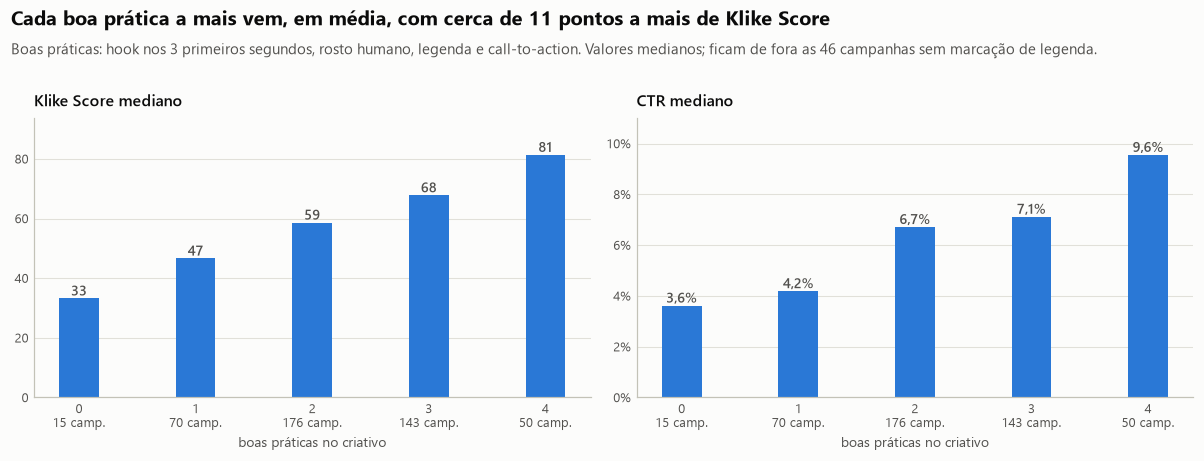

Mantendo plataforma, categoria, objetivo, público e densidade de texto iguais, cada boa prática a mais se associa a 11,4 pontos a mais de Klike Score (intervalo de 95%: 10,5 a 12,2).
CTR mediano com as 4 práticas vs. nenhuma: 2,6 vezes


In [6]:
known = df.dropna(subset=["boas_praticas"])
staircase = known.groupby("boas_praticas").agg(
    campanhas=("campaign_id", "size"),
    score=(TARGET, "median"),
    ctr=("ctr", "median"),
)
staircase.index = staircase.index.astype(int)

fit = smf.ols(
    f"{TARGET} ~ boas_praticas + text_density + {CONTEXT_FORMULA}",
    data=modeling_frame(known),
).fit(cov_type="HC3")
points, (low, high) = fit.params["boas_praticas"], fit.conf_int().loc["boas_praticas"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
panels = [
    ("score", "Klike Score mediano", lambda v: fmt_number(v, 0)),
    ("ctr", "CTR mediano", lambda v: fmt_pct(v, 1)),
]
for ax, (col, title, label) in zip(axes, panels, strict=True):
    ax.bar(staircase.index, staircase[col], width=0.34, color=viz.ACCENT)
    for x, value in staircase[col].items():
        ax.text(x, value, label(value), ha="center", va="bottom", fontsize=9,
                color=viz.INK_SECONDARY, fontweight="semibold")
    ax.set_xticks(
        staircase.index,
        [f"{i}\n{n} camp." for i, n in staircase["campanhas"].items()],
    )
    ax.set_xlabel("boas práticas no criativo")
    ax.set_ylim(0, staircase[col].max() * 1.15)
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
axes[0].yaxis.set_major_formatter(viz.compact_formatter)
axes[1].yaxis.set_major_formatter(viz.pct_formatter)

viz.add_header(
    fig,
    "Cada boa prática a mais vem, em média, com cerca de 11 pontos a mais de Klike Score",
    "Boas práticas: hook nos 3 primeiros segundos, rosto humano, legenda e call-to-action. "
    "Valores medianos; ficam de fora as 46 campanhas sem marcação de legenda.",
)
viz.save(fig, "02_boas_praticas")
plt.show()

print(
    f"Mantendo plataforma, categoria, objetivo, público e densidade de texto iguais, cada boa "
    f"prática a mais se associa a {fmt_number(points, 1)} pontos a mais de Klike Score "
    f"(intervalo de 95%: {fmt_number(low, 1)} a {fmt_number(high, 1)})."
)
print(
    f"CTR mediano com as 4 práticas vs. nenhuma: "
    f"{fmt_number(staircase.loc[4, 'ctr'] / staircase.loc[0, 'ctr'], 1)} vezes"
)

A escada é a mensagem mais simples para um time de criação. Duas ressalvas para não simplificar demais:

- **As práticas não pesam igual.** Os 11 pontos são uma média. A seção 2.4 mostra que o hook se associa a cerca de 17 pontos, e legenda e CTA, a cerca de 8.
- **No CTR, quem puxa a escada é o hook e o rosto.** Legenda e CTA não mostram efeito robusto no CTR, como a próxima seção mostra.

### 2.2 O efeito de cada atributo, métrica por métrica

Esta seção e as duas seguintes respondem às duas famílias de testes da Parte 1.2: atributos × métricas de performance e atributos × Klike Score. Os testes de cada família são calculados juntos, para a correção valer sobre o conjunto.

In [7]:
METRICS = {
    "ctr": "CTR",
    "engagement_rate": "Engajamento",
    "completion_rate": "Retenção",
    "conversion_rate": "Conversão\npor clique",
    "conversions_per_mille": "Conversões por\nmil impressões",
    "roas_non_branding": "ROAS",
}
FAMILY_NAMES = {
    **{metric: name.replace("\n", " ") for metric, name in METRICS.items()},
    "ticket": "Ticket médio",
    "cpc": "CPC",
}
MUSIC = "+0,1 de música"

def part_1_2_tests(data: pd.DataFrame):
    """Todos os testes da Parte 1.2 sobre uma base: tabelas por métrica e as duas famílias.

    Fica numa função para a seção 2.5 refazer exatamente os mesmos testes sem as
    campanhas corrigidas por plausibilidade.
    """
    overall = {metric: estimate_effects(data, metric, terms=TERMS) for metric in METRICS}
    roas_parts = {
        "ticket": estimate_effects(
            data[data["flag_roas_applicable"] & (data["conversions"] > 0)].assign(
                ticket=lambda d: d["revenue"] / d["conversions"]
            ),
            "ticket",
            terms=TERMS,
        ),
        "cpc": estimate_effects(data, "cpc", terms=TERMS),
    }
    music = {
        metric: tidy_effects(
            fit_model(data, metric, log=metric != TARGET, extra="musica_decimos"),
            {"musica_decimos": MUSIC},
            log=metric != TARGET,
        )
        for metric in ["ctr", "engagement_rate", "completion_rate", "roas_non_branding", TARGET]
    }
    performance = add_evidence(
        pd.concat(
            [table.assign(metrica=metric) for metric, table in {**overall, **roas_parts}.items()]
            + [table.assign(metrica=metric) for metric, table in music.items() if metric != TARGET],
            ignore_index=True,
        )
    )
    score = add_evidence(
        pd.concat(
            [estimate_effects(data, TARGET, log=False, terms=TERMS), music[TARGET]],
            ignore_index=True,
        ).assign(metrica=TARGET)
    )
    return overall, music, performance, score


overall, music, performance_family, score_family = part_1_2_tests(df)
for name, family in [("atributos × performance", performance_family),
                     ("atributos × Klike Score", score_family)]:
    levels = family["evidencia"].value_counts()
    print(
        f"Família {name}: {len(family)} testes | p < 0,05: {(family['p_valor'] < 0.05).sum()} | "
        f"robustos: {levels.get('robusto', 0)} | indícios: {levels.get('indício', 0)}"
    )
by_test = performance_family.set_index(["metrica", "atributo"])


def labeled(index: pd.DataFrame, metric: str, attribute: str, show=fmt_signed_pct) -> str:
    """Efeito formatado, com o nível de evidência ao lado quando não é robusto."""
    row = index.loc[(metric, attribute)]
    return show(row["efeito"]) + LEVEL_SUFFIX[row["evidencia"]]

Família atributos × performance: 60 testes | p < 0,05: 17 | robustos: 15 | indícios: 2
Família atributos × Klike Score: 8 testes | p < 0,05: 8 | robustos: 8 | indícios: 0


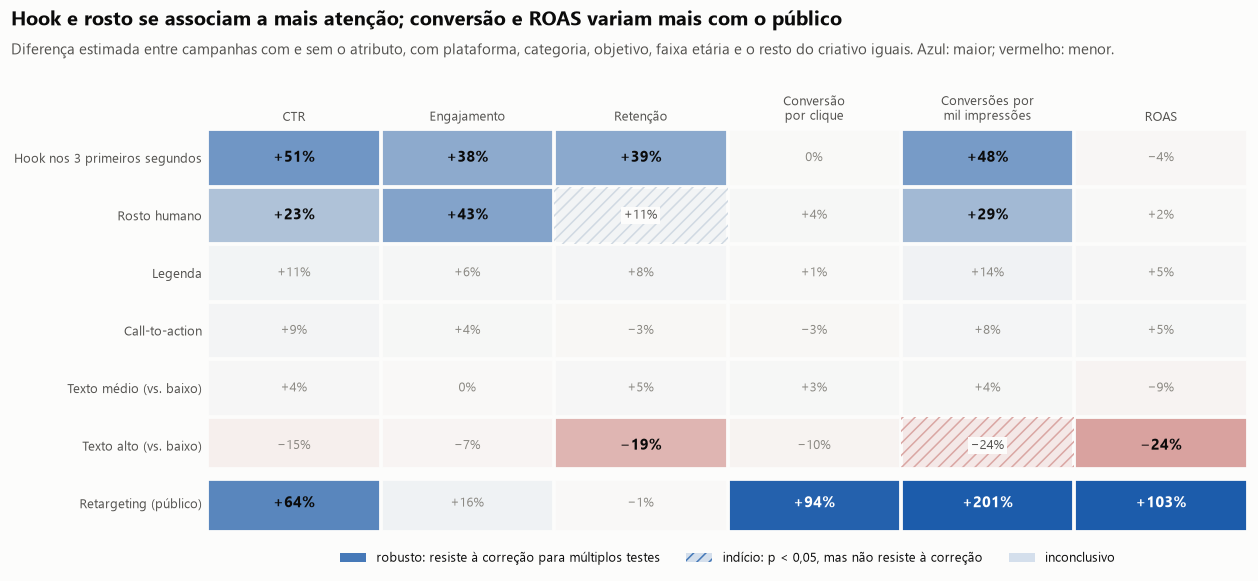

,CTR (n=500),Engajamento (n=468),Retenção (n=437),Conversão por clique (n=481),Conversões por mil impressões (n=481),ROAS (n=424)
atributo,,,,,,
Hook nos 3 primeiros segundos,"+51% [+31%, +75%]","+38% [+16%, +65%]","+39% [+26%, +53%]","0% [−8%, +10%] (inconclusivo)","+48% [+26%, +75%]","−4% [−17%, +10%] (inconclusivo)"
Rosto humano,"+23% [+7%, +42%]","+43% [+20%, +69%]","+11% [0%, +23%] (indício)","+4% [−5%, +13%] (inconclusivo)","+29% [+10%, +52%]","+2% [−11%, +18%] (inconclusivo)"
Legenda,"+11% [−4%, +28%] (inconclusivo)","+6% [−12%, +27%] (inconclusivo)","+8% [−3%, +19%] (inconclusivo)","+1% [−8%, +11%] (inconclusivo)","+14% [−4%, +35%] (inconclusivo)","+5% [−9%, +20%] (inconclusivo)"
Call-to-action,"+9% [−6%, +27%] (inconclusivo)","+4% [−15%, +26%] (inconclusivo)","−3% [−13%, +8%] (inconclusivo)","−3% [−12%, +7%] (inconclusivo)","+8% [−9%, +28%] (inconclusivo)","+5% [−9%, +21%] (inconclusivo)"
Texto médio (vs. baixo),"+4% [−11%, +23%] (inconclusivo)","0% [−18%, +21%] (inconclusivo)","+5% [−6%, +17%] (inconclusivo)","+3% [−6%, +14%] (inconclusivo)","+4% [−14%, +25%] (inconclusivo)","−9% [−21%, +6%] (inconclusivo)"
Texto alto (vs. baixo),"−15% [−31%, +4%] (inconclusivo)","−7% [−27%, +18%] (inconclusivo)","−19% [−29%, −7%]","−10% [−21%, +3%] (inconclusivo)","−24% [−40%, −3%] (indício)","−24% [−38%, −7%]"
Retargeting (público),"+64% [+41%, +91%]","+16% [−4%, +41%] (inconclusivo)","−1% [−13%, +12%] (inconclusivo)","+94% [+75%, +115%]","+201% [+152%, +260%]","+103% [+73%, +138%]"


Indício: Rosto humano, Retenção: +11% (p = 0,045, q = 0,16)
Indício: Texto alto (vs. baixo), Conversões por mil impressões: −24% (p = 0,025, q = 0,09)


In [8]:
def family_grid(family: pd.DataFrame, column: str) -> pd.DataFrame:
    """Uma coluna da família no formato do mapa: atributos nas linhas, métricas nas colunas."""
    grid = family[family["metrica"].isin(list(METRICS)) & family["atributo"].isin(TERMS.values())]
    return (
        grid.pivot(index="atributo", columns="metrica", values=column)
        .loc[list(TERMS.values()), list(METRICS)]
        .rename(columns=METRICS)
    )


def effects_with_ci(effects: dict, labels: dict, levels: pd.Series | None = None) -> pd.DataFrame:
    """Tabela legível: efeito e intervalo de 95% de cada atributo em cada métrica.

    Com ``levels``, indícios e resultados inconclusivos ganham a marcação ao lado.
    """
    columns = {}
    for metric, table in effects.items():
        name = labels[metric].replace("\n", " ") + f" (n={table.attrs['n']})"
        columns[name] = table.set_index("atributo").apply(
            lambda r, m=metric: f"{fmt_signed_pct(r.efeito)} "
            f"[{fmt_signed_pct(r.ic_inferior)}, {fmt_signed_pct(r.ic_superior)}]"
            + (LEVEL_SUFFIX[levels[(m, r.name)]] if levels is not None else ""),
            axis=1,
        )
    return pd.DataFrame(columns)


def faded(rgba):
    """A mesma cor, apagada contra o fundo: usada para o que não é robusto.

    Aceita uma cor RGBA ou uma matriz delas, uma por linha.
    """
    return 0.22 * np.asarray(rgba) + 0.78 * np.array(to_rgba(viz.SURFACE))


def effect_grid(ax, values: pd.DataFrame, levels: pd.DataFrame):
    """Mapa de efeitos: azul é maior, vermelho é menor; a força da cor segue a evidência."""
    limit = np.log(2.0)  # escala simétrica em razão: de -50% a +100%
    scaled = np.clip((np.log1p(values.to_numpy(dtype=float)) + limit) / (2 * limit), 0, 1)
    full = viz.DIVERGING(scaled)
    level = levels.to_numpy()
    colors = full.copy()
    weak = level != "robusto"
    colors[weak] = faded(full[weak])
    ax.imshow(colors, aspect="auto")
    text_color = {"indício": viz.INK_SECONDARY, "inconclusivo": viz.INK_MUTED}
    label_box = {"boxstyle": "square,pad=0.2", "facecolor": viz.SURFACE, "edgecolor": "none"}
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            strong, weak_signal = level[i, j] == "robusto", level[i, j] == "indício"
            if weak_signal:
                ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, hatch="///",
                                       edgecolor=full[i, j], linewidth=0))
            ax.text(
                j, i, fmt_signed_pct(values.iat[i, j]), ha="center", va="center",
                fontsize=9.5 if strong else 8.5,
                fontweight="bold" if strong else "normal",
                color=viz.ink_on(colors[i, j]) if strong else text_color[level[i, j]],
                bbox=label_box if weak_signal else None,
            )
    ax.set_xticks(range(values.shape[1]), values.columns)
    ax.set_yticks(range(values.shape[0]), values.index)
    ax.xaxis.tick_top()
    ax.set_xticks(np.arange(-0.5, values.shape[1]), minor=True)
    ax.set_yticks(np.arange(-0.5, values.shape[0]), minor=True)
    ax.grid(which="minor", color=viz.SURFACE, linewidth=2.5)
    ax.grid(which="major", visible=False)
    ax.tick_params(which="both", length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    blue = np.array(viz.DIVERGING(0.9))
    ax.legend(
        handles=[
            Patch(facecolor=blue, label="robusto: resiste à correção para múltiplos testes"),
            Patch(facecolor=faded(blue), edgecolor=blue, hatch="///", linewidth=0,
                  label="indício: p < 0,05, mas não resiste à correção"),
            Patch(facecolor=faded(blue), label="inconclusivo"),
        ],
        loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=3,
    )


fig, ax = plt.subplots(figsize=(11.5, 5.4))
effect_grid(ax, family_grid(performance_family, "efeito"),
            family_grid(performance_family, "evidencia"))
ax.axhline(len(CREATIVE_TERMS) - 0.5, color=viz.SURFACE, linewidth=9)
viz.add_header(
    fig,
    "Hook e rosto se associam a mais atenção; conversão e ROAS variam mais com o público",
    "Diferença estimada entre campanhas com e sem o atributo, com plataforma, categoria, "
    "objetivo, faixa etária e o resto do criativo iguais. Azul: maior; vermelho: menor.",
)
viz.save(fig, "02_efeitos_geral")
plt.show()

display(effects_with_ci(overall, METRICS, by_test["evidencia"]))
for row in performance_family[performance_family["evidencia"] == "indício"].itertuples():
    print(
        f"Indício: {row.atributo}, {FAMILY_NAMES[row.metrica]}: {fmt_signed_pct(row.efeito)} "
        f"({p_text(row.p_valor)}, q = {fmt_number(row.q_valor, 2)})"
    )

Quatro leituras:

1. **Hook e rosto são os atributos que mais pesam, e pesam na atenção.** Campanhas com hook têm CTR, engajamento e retenção maiores; com rosto, engajamento e CTR maiores, e só um indício de retenção maior. Hook é o mais forte nos cliques e na retenção; rosto, no engajamento.
2. **Não há evidência de que hook e rosto se associem à conversão de quem clica ou ao ROAS.** Isso não quer dizer que não tenham relação com vendas. Como recebem mais cliques, campanhas com hook e rosto têm mais **conversões por mil impressões**. O ROAS não acompanha por um motivo de conta: ROAS é conversão por clique, vezes ticket médio, dividido pelo CPC. A tabela abaixo mostra que nenhum dos três tem diferença detectável com hook ou rosto. Mais cliques significam mais gasto na mesma proporção.
3. **Texto demais anda com desempenho pior.** Densidade alta vem com retenção e ROAS menores, e com um indício de menos conversões por mil impressões. É o único atributo do criativo associado ao ROAS: o ticket médio é menor, e pequenas diferenças na conversão e no CPC, inconclusivas sozinhas, se somam a isso. Esse resultado no ROAS é robusto na base completa, mas o seu nível de evidência é sensível às correções por plausibilidade, como mostra a seção 2.5. Já a densidade média, comparada à baixa, não mostra diferença clara.
4. **Retargeting, que é decisão de público e não de criativo, é o que mais se associa a conversão e ROAS:** com retargeting, os dois são cerca de duas vezes maiores. Ele está no gráfico como referência, para mostrar o tamanho do efeito do público perto do efeito do criativo.

Legenda e CTA não mostram efeito robusto em nenhuma métrica de performance. A legenda tem só o indício nas conversões por mil impressões que aparece na binomial negativa, como mostrou a seção 1.

In [9]:
rows = ["Hook nos 3 primeiros segundos", "Rosto humano", "Texto alto (vs. baixo)"]
decomposition = {
    "Conversão por clique": "conversion_rate",
    "Ticket médio (receita por conversão)": "ticket",
    "CPC": "cpc",
}
display(
    pd.DataFrame(
        {name: [labeled(by_test, metric, row) for row in rows]
         for name, metric in decomposition.items()},
        index=rows,
    ).rename_axis("ROAS = conversão × ticket ÷ CPC")
)

,Conversão por clique,Ticket médio (receita por conversão),CPC
ROAS = conversão × ticket ÷ CPC,,,
Hook nos 3 primeiros segundos,0% (inconclusivo),−1% (inconclusivo),+3% (inconclusivo)
Rosto humano,+4% (inconclusivo),−1% (inconclusivo),−3% (inconclusivo)
Texto alto (vs. baixo),−10% (inconclusivo),−9%,+9% (inconclusivo)


### 2.3 Proporção música/voz

A proporção entre música e voz é contínua, de 0, só voz, a 1, só música. Ela fica fora do modelo principal porque falta em 38 campanhas. Aqui, o efeito é lido a cada 0,1 a mais de música, com o mesmo controle de contexto e do resto do criativo.

In [10]:
score_tests = score_family.set_index(["metrica", "atributo"])
display(
    pd.DataFrame(
        {
            METRIC_NAMES[metric]: [
                labeled(score_tests, metric, MUSIC, lambda v: fmt_signed(v, 2, " pts"))
                if metric == TARGET
                else labeled(by_test, metric, MUSIC, lambda v: fmt_signed_pct(v, 1))
            ]
            for metric in music
        },
        index=["a cada +0,1 de música"],
    )
)

,CTR,Engajamento,Retenção,ROAS,Klike Score
"a cada +0,1 de música","+1,2% (inconclusivo)","+2,9% (inconclusivo)","+3,9%","−0,5% (inconclusivo)","−0,45 pts"


Mais música se associa a um pouco mais de retenção, e a um score um pouco menor. Os efeitos são pequenos a cada 0,1 e não aparecem em CTR, engajamento ou ROAS. É um atributo de ajuste fino, não uma alavanca principal.

### 2.4 E o Klike Score?

O mesmo modelo, agora com o Klike Score como resultado, em pontos, lado a lado com as métricas de performance em que cada atributo tem efeito robusto:

In [11]:
score_by_attribute = score_family.set_index("atributo")
# A música é lida a cada +0,1: o efeito é pequeno e pede duas casas decimais.
decimals = [2 if attribute == MUSIC else 1 for attribute in score_by_attribute.index]


def performance_summary(attribute: str) -> str:
    """Métricas de performance em que o atributo tem efeito robusto, e os indícios."""
    tests = performance_family[performance_family["atributo"] == attribute]
    parts = []
    for level, prefix in [("robusto", ""), ("indício", "indício: ")]:
        hits = tests[tests["evidencia"] == level]
        if len(hits):
            parts.append(prefix + ", ".join(
                f"{FAMILY_NAMES[r.metrica]} {fmt_signed_pct(r.efeito)}" for r in hits.itertuples()
            ))
    return "; ".join(parts) or "nenhuma"


display(
    pd.DataFrame(
        {
            "Klike Score": [
                fmt_signed(v, d, " pts")
                for v, d in zip(score_by_attribute["efeito"], decimals, strict=True)
            ],
            "intervalo": [
                f"{fmt_signed(a, d)} a {fmt_signed(b, d)}"
                for a, b, d in zip(score_by_attribute["ic_inferior"],
                                   score_by_attribute["ic_superior"], decimals, strict=True)
            ],
            "evidência": score_by_attribute["evidencia"],
            "em performance": [performance_summary(a) for a in score_by_attribute.index],
        },
        index=score_by_attribute.index,
    )
)

,Klike Score,intervalo,evidência,em performance
atributo,,,,
Hook nos 3 primeiros segundos,"+17,1 pts","+15,6 a +18,7",robusto,"CTR +51%, Engajamento +38%, Retenção +39%, Conversões por mil impressões +48%"
Rosto humano,"+11,8 pts","+10,2 a +13,3",robusto,"CTR +23%, Engajamento +43%, Conversões por mil impressões +29%; indício: Retenção +11%"
Legenda,"+8,3 pts","+6,7 a +9,8",robusto,nenhuma
Call-to-action,"+8,2 pts","+6,5 a +9,8",robusto,nenhuma
Texto médio (vs. baixo),"+6,9 pts","+5,2 a +8,6",robusto,nenhuma
Texto alto (vs. baixo),"−7,4 pts","−9,8 a −5,1",robusto,"Retenção −19%, ROAS −24%, Ticket médio −9%; indício: Conversões por mil impressões −24%"
Retargeting (público),"+4,5 pts","+2,9 a +6,1",robusto,"CTR +64%, Conversão por clique +94%, Conversões por mil impressões +201%, ROAS +103%"
"+0,1 de música","−0,45 pts","−0,87 a −0,04",robusto,Retenção +4%


Duas conclusões:

- **O score se comporta como uma medida do criativo, não do público.** Campanhas com retargeting convertem cerca de duas vezes mais, mas têm só 4,5 pontos a mais de score; com hook, são 17 pontos a mais. Isso é boa notícia para a Parte 2: um modelo que só enxerga o criativo e o contexto, antes da veiculação, deve conseguir prever boa parte do score.
- **O score e a performance nem sempre concordam.** Eles concordam sobre hook, rosto e texto alto. Mas o score dá de 7 a 8 pontos para legenda, CTA e texto médio, que não mostram efeito robusto em nenhuma métrica de performance nesta base. A legenda tem só um indício em conversões por mil impressões, que depende do modelo. Talvez esses efeitos existam e sejam pequenos demais para aparecer com clareza em 500 campanhas; talvez o score siga boas práticas de mercado que estes dados não confirmam. De todo modo, é algo que eu levaria ao time da Klike: vale validar esses pesos com testes controlados. Para o engine, a consequência é concreta: recomendar um CTA tende a subir o score, mas não há evidência de que melhore a performance, e a recomendação precisa dizer isso.

### 2.5 As correções por plausibilidade mudam alguma conclusão?

Na Parte 1.1, 5 das 10 correções de dados se apoiam em plausibilidade, não em duas contas independentes. Para ver o quanto as conclusões dependem delas, refiz a análise sem essas 5 campanhas: primeiro os efeitos principais, depois os níveis de evidência das duas famílias de testes desta seção. As conversões por mil impressões entram na primeira tabela porque são a métrica que as correções de impressões afetam diretamente.

In [12]:
cleaning = clean(load_raw())
plausibility_ids = set(cleaning.log.loc[cleaning.log["basis"] == PLAUSIBILITY, "campaign_id"])
without = df[~df["campaign_id"].isin(plausibility_ids)]
CORRECTION_CHECKS = [
    (TARGET, "Hook nos 3 primeiros segundos", "Hook, no Klike Score"),
    ("ctr", "Hook nos 3 primeiros segundos", "Hook, no CTR"),
    ("engagement_rate", "Rosto humano", "Rosto, no engajamento"),
    ("conversions_per_mille", "Hook nos 3 primeiros segundos",
     "Hook, nas conversões por mil impressões"),
    ("conversions_per_mille", "Texto alto (vs. baixo)",
     "Texto alto, nas conversões por mil impressões"),
]
correction_check = {}
for name, data in {
    "todas as campanhas": df,
    "sem as 5 corrigidas por plausibilidade": without,
}.items():
    column = {}
    for metric, attribute, label in CORRECTION_CHECKS:
        log = metric != TARGET
        effect = estimate_effects(data, metric, log=log).set_index("atributo").loc[attribute]
        value = effect["efeito"]
        text = fmt_signed_pct(value, 1) if log else fmt_signed(value, 2, " pts")
        column[label] = text + ("" if effect["significativo"] else " (inconclusivo)")
    correction_check[f"{name} ({len(data)} camp.)"] = column
display(pd.DataFrame(correction_check).rename_axis("efeito estimado"))

,todas as campanhas (500 camp.),sem as 5 corrigidas por plausibilidade (495 camp.)
efeito estimado,,
"Hook, no Klike Score","+17,14 pts","+17,09 pts"
"Hook, no CTR","+51,3%","+51,1%"
"Rosto, no engajamento","+42,7%","+43,5%"
"Hook, nas conversões por mil impressões","+48,3%","+48,8%"
"Texto alto, nas conversões por mil impressões","−23,7%","−20,9%"


In [13]:
def describe(effect: float, q_value: float, level: str, metric: str) -> str:
    """Efeito, q-valor e nível de evidência de um teste, numa linha."""
    shown = fmt_signed(effect, 1, " pts") if metric == TARGET else fmt_signed_pct(effect)
    return f"{shown}, q = {fmt_number(q_value, 3)}, {level}"


_, _, performance_without, score_without = part_1_2_tests(without)
level_changes = pd.concat(
    [
        full.merge(reduced, on=["metrica", "atributo"], suffixes=("", "_sem"))
        for full, reduced in [(performance_family, performance_without),
                              (score_family, score_without)]
    ],
    ignore_index=True,
).query("evidencia != evidencia_sem")
total_tests = len(performance_family) + len(score_family)
print(f"Níveis de evidência que mudam sem as 5 campanhas: {len(level_changes)} de {total_tests}")
display(
    pd.DataFrame(
        {
            "todas as campanhas": [
                describe(r.efeito, r.q_valor, r.evidencia, r.metrica)
                for r in level_changes.itertuples()
            ],
            "sem as 5": [
                describe(r.efeito_sem, r.q_valor_sem, r.evidencia_sem, r.metrica)
                for r in level_changes.itertuples()
            ],
        },
        index=[
            f"{r.atributo}, {FAMILY_NAMES.get(r.metrica, 'Klike Score')}"
            for r in level_changes.itertuples()
        ],
    )
)

Níveis de evidência que mudam sem as 5 campanhas: 1 de 68


,todas as campanhas,sem as 5
"Texto alto (vs. baixo), ROAS","−24%, q = 0,028, robusto","−22%, q = 0,055, indício"


**Os principais efeitos ficam próximos, mas um nível de evidência muda.** Sem as 5 campanhas, os efeitos no Klike Score, no CTR e no engajamento mudam menos de um ponto. Nas conversões por mil impressões, a métrica mais exposta às correções, o hook fica em torno de +49%, e o texto alto vai de −24% para −21%, ainda só um indício. Dos 68 níveis de evidência das duas famílias, 67 se mantêm. A exceção é o texto alto no ROAS: o efeito quase não muda, de −24% para −22%, mas o q-valor sobe de 0,028 para 0,055, e o resultado passa de robusto a indício.

A leitura que fica: a associação entre muito texto e ROAS menor aparece com ou sem essas campanhas, mas o seu nível de evidência é sensível a elas. A análise principal continua usando a base completa, porque as correções são a melhor reconstrução disponível dos dados, e essa sensibilidade fica registrada junto do resultado, na seção 2.2.

## 3. Parte 1.3 · O que funciona no TikTok funciona no LinkedIn?

### 3.1 As plataformas têm patamares diferentes

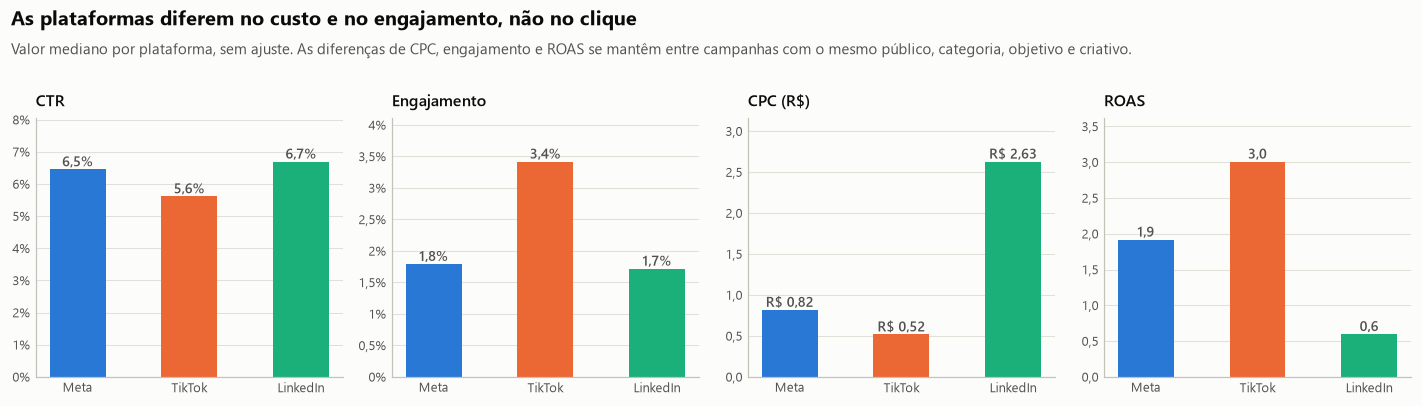

,CTR,Engajamento,Retenção,Conversão por clique,ROAS,Klike Score,CPC
mediana por plataforma,,,,,,,
Meta,"6,5%","1,8%",52%,"2,9%","1,92","60,5","R$ 0,82"
TikTok,"5,6%","3,4%",50%,"3,1%","3,01","62,0","R$ 0,52"
LinkedIn,"6,7%","1,7%",50%,"3,2%","0,60","57,2","R$ 2,63"
p-valor da diferença,"0,625","< 0,001","0,190","0,815","< 0,001","0,055","< 0,001"
q-valor (7 testes),"0,730","< 0,001","0,267","0,815","< 0,001","0,096","< 0,001"


In [14]:
BENCHMARKS = {
    "ctr": ("CTR", viz.pct_formatter, lambda v: fmt_pct(v, 1)),
    "engagement_rate": ("Engajamento", viz.pct_formatter, lambda v: fmt_pct(v, 1)),
    "cpc": ("CPC (R$)", viz.decimal_formatter(1), lambda v: "R$ " + fmt_number(v, 2)),
    "roas_non_branding": ("ROAS", viz.decimal_formatter(1), lambda v: fmt_number(v, 1)),
}
medians = df.groupby("platform", observed=True)[list(BENCHMARKS)].median().loc[PLATFORMS]

fig, axes = plt.subplots(1, 4, figsize=(13, 3.8))
for ax, (metric, (title, formatter, label)) in zip(axes, BENCHMARKS.items(), strict=True):
    ax.bar(PLATFORMS, medians[metric], width=0.5,
           color=[viz.PLATFORM_COLORS[p] for p in PLATFORMS])
    for x, value in enumerate(medians[metric]):
        ax.text(x, value, label(value), ha="center", va="bottom", fontsize=9,
                color=viz.INK_SECONDARY, fontweight="semibold")
    ax.set_ylim(0, medians[metric].max() * 1.2)
    ax.yaxis.set_major_formatter(formatter)
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
viz.add_header(
    fig,
    "As plataformas diferem no custo e no engajamento, não no clique",
    "Valor mediano por plataforma, sem ajuste. As diferenças de CPC, engajamento e ROAS se "
    "mantêm entre campanhas com o mesmo público, categoria, objetivo e criativo.",
)
viz.save(fig, "02_patamares_por_plataforma")
plt.show()

SUMMARY_FORMATS = {
    "ctr": lambda v: fmt_pct(v, 1),
    "engagement_rate": lambda v: fmt_pct(v, 1),
    "completion_rate": lambda v: fmt_pct(v, 0),
    "conversion_rate": lambda v: fmt_pct(v, 1),
    "roas_non_branding": lambda v: fmt_number(v, 2),
    TARGET: lambda v: fmt_number(v, 1),
    "cpc": lambda v: "R$ " + fmt_number(v, 2),
}
groups = {p: g for p, g in df.groupby("platform", observed=True)}
kruskal = pd.Series(
    {
        metric: stats.kruskal(*(g[metric].dropna() for g in groups.values())).pvalue
        for metric in SUMMARY_FORMATS
    }
)
kruskal_q = pd.Series(stats.false_discovery_control(kruskal, method="bh"), index=kruskal.index)
platform_summary = pd.DataFrame(
    {
        METRIC_NAMES.get(metric, "CPC"): [
            *(show(groups[p][metric].median()) for p in PLATFORMS),
            fmt_p(kruskal[metric]),
            fmt_p(kruskal_q[metric]),
        ]
        for metric, show in SUMMARY_FORMATS.items()
    },
    index=[*PLATFORMS, "p-valor da diferença", "q-valor (7 testes)"],
)
display(platform_summary.rename_axis("mediana por plataforma"))

Essas medianas são uma comparação direta. Elas só dizem algo sobre a plataforma se as campanhas de cada uma forem parecidas. A mistura de categorias, objetivos e retargeting é parecida nas três, mas a de faixa etária não:

In [15]:
for name, column in [("categoria", "category"), ("objetivo", "objective"),
                     ("retargeting", "is_retargeting"), ("faixa etária", "target_audience_age")]:
    p = stats.chi2_contingency(pd.crosstab(df["platform"], df[column])).pvalue
    print(f"A mistura de {name} difere entre plataformas? {p_text(p)}")
display(
    (pd.crosstab(df["platform"], df["target_audience_age"], normalize="index") * 100)
    .round(0)
    .astype(int)
    .loc[PLATFORMS]
    .rename_axis("% das campanhas")
)

A mistura de categoria difere entre plataformas? p = 0,975
A mistura de objetivo difere entre plataformas? p = 0,567
A mistura de retargeting difere entre plataformas? p = 0,516
A mistura de faixa etária difere entre plataformas? p < 0,001


target_audience_age,18-24,25-34,35-44,45+
% das campanhas,,,,
Meta,24,27,32,17
TikTok,44,31,17,8
LinkedIn,2,28,40,30


Para separar a plataforma da composição, a tabela abaixo compara campanhas com o mesmo público, categoria, objetivo, retargeting e atributos do criativo. Nas taxas, os números são razões: 1,76× quer dizer 76% acima. No Klike Score, são diferenças em pontos.

In [16]:
CONTRASTS = {
    "TikTok vs. Meta": ("TikTok", "Meta", "C(platform)[T.TikTok]"),
    "LinkedIn vs. Meta": ("LinkedIn", "Meta", "C(platform)[T.LinkedIn]"),
    "LinkedIn vs. TikTok": (
        "LinkedIn", "TikTok", "C(platform)[T.LinkedIn] - C(platform)[T.TikTok]"
    ),
}
contrast_rows = []
for metric in SUMMARY_FORMATS:
    log = metric != TARGET
    to_scale = np.exp if log else float  # razão nas taxas, diferença em pontos no score
    fit = fit_model(df, metric, log=log)
    for name, (platform, reference, contrast) in CONTRASTS.items():
        test = fit.t_test(f"{contrast} = 0")
        low, high = np.squeeze(test.conf_int())
        platform_median = groups[platform][metric].median()
        reference_median = groups[reference][metric].median()
        contrast_rows.append(
            {
                "métrica": METRIC_NAMES.get(metric, "CPC"),
                "comparação": name,
                "log": log,
                "direta": (platform_median / reference_median if log
                           else platform_median - reference_median),
                "ajustada": to_scale(np.squeeze(test.effect)),
                "ic_inferior": to_scale(low),
                "ic_superior": to_scale(high),
                "p_valor": float(np.squeeze(test.pvalue)),
            }
        )
contrasts = add_evidence(pd.DataFrame(contrast_rows))


def show_contrast(value: float, log: bool) -> str:
    """Razão nas taxas (1,76×) e diferença em pontos no Klike Score (+2,8 pts)."""
    return f"{fmt_number(value, 2)}×" if log else fmt_signed(value, 1, " pts")


def show_bound(value: float, log: bool) -> str:
    """Limite do intervalo, sem repetir a unidade."""
    return fmt_number(value, 2) if log else fmt_signed(value, 1)


DIRECT, ADJUSTED = "direta (medianas)", "ajustada (intervalo de 95%)"
contrasts[DIRECT] = [show_contrast(r.direta, r.log) for r in contrasts.itertuples()]
contrasts[ADJUSTED] = [
    f"{show_contrast(r.ajustada, r.log)} "
    f"({show_bound(r.ic_inferior, r.log)} a {show_bound(r.ic_superior, r.log)})"
    + LEVEL_SUFFIX[r.evidencia]
    for r in contrasts.itertuples()
]
adjusted_table = contrasts.pivot_table(
    index="métrica", columns="comparação", values=[DIRECT, ADJUSTED],
    aggfunc="first", sort=False,
).swaplevel(axis=1)
display(adjusted_table[[(c, v) for c in CONTRASTS for v in [DIRECT, ADJUSTED]]])

comparação             TikTok vs. Meta                                      \
                     direta (medianas)         ajustada (intervalo de 95%)   
métrica                                                                      
CTR                              0,87×  0,97× (0,83 a 1,13) (inconclusivo)   
Engajamento                      1,91×                 1,76× (1,45 a 2,13)   
Retenção                         0,95×  0,91× (0,81 a 1,02) (inconclusivo)   
Conversão por clique             1,05×  1,04× (0,94 a 1,15) (inconclusivo)   
ROAS                             1,57×                 1,69× (1,47 a 1,95)   
Klike Score                   +1,5 pts              +2,8 pts (+1,0 a +4,5)   
CPC                              0,63×                 0,65× (0,61 a 0,69)   

comparação           LinkedIn vs. Meta                                      \
                     direta (medianas)         ajustada (intervalo de 95%)   
métrica                                                                      
CTR                              1,04×  0,97× (0,78 a 1,20) (inconclusivo)   
Engajamento                      0,96×  0,90× (0,69 a 1,18) (inconclusivo)   
Retenção                         0,96×  0,99× (0,86 a 1,13) (inconclusivo)   
Conversão por clique             1,09×  1,01× (0,89 a 1,15) (inconclusivo)   
ROAS                             0,31×                 0,38× (0,30 a 0,48)   
Klike Score                   −3,3 pts              −3,7 pts (−6,0 a −1,4)   
CPC                              3,21×                 2,98× (2,58 a 3,43)   

comparação           LinkedIn vs. TikTok                                      
                       direta (medianas)         ajustada (intervalo de 95%)  
métrica                                                                       
CTR                                1,19×  1,00× (0,79 a 1,26) (inconclusivo)  
Engajamento                        0,50×                 0,51× (0,38 a 0,68)  
Retenção                           1,01×  1,09× (0,94 a 1,27) (inconclusivo)  
Conversão por clique               1,04×  0,97× (0,85 a 1,11) (inconclusivo)  
ROAS                               0,20×                 0,22× (0,17 a 0,29)  
Klike Score                     −4,8 pts              −6,5 pts (−9,0 a −3,9)  
CPC                                5,06×                 4,59× (3,95 a 5,33)

- **O clique custa muito mais no LinkedIn:** entre campanhas parecidas, o CPC do LinkedIn é 4,6 vezes o do TikTok, contra 5,1 vezes na comparação direta. O ROAS do LinkedIn fica 62% abaixo do da Meta, e o do TikTok, 69% acima.
- **O engajamento do TikTok é bem maior:** 76% acima do da Meta entre campanhas parecidas, e quase o dobro do do LinkedIn.
- **CTR, retenção e conversão por clique não diferem** entre plataformas de forma detectável, nem na comparação direta nem na ajustada.
- **O Klike Score difere depois do ajuste:** comparadas a campanhas parecidas da Meta, as do TikTok têm cerca de 3 pontos a mais, e as do LinkedIn, cerca de 4 a menos. Na comparação direta, a diferença não chegava a ser significativa.

**A composição não explica as diferenças de patamar.** A faixa etária muda muito entre plataformas, mas, com o público mantido igual, as diferenças de CPC, engajamento e ROAS continuam com tamanho parecido.

Consequência prática: **um mesmo número significa coisas diferentes em cada plataforma.** Um engajamento de 2% está na média da Meta e bem abaixo da mediana do TikTok. Toda comparação de criativos deve ser feita contra o patamar da própria plataforma.

### 3.2 Os atributos funcionam do mesmo jeito em cada plataforma?

Um erro comum aqui é rodar a análise em cada plataforma e comparar quais efeitos deram significativos. Isso engana: um efeito pode ser significativo na Meta e não no LinkedIn só porque o LinkedIn tem três vezes menos campanhas. O teste certo compara os efeitos diretamente e pergunta se a diferença entre plataformas é maior do que o acaso explicaria.

Primeiro, os efeitos estimados dentro de cada plataforma:

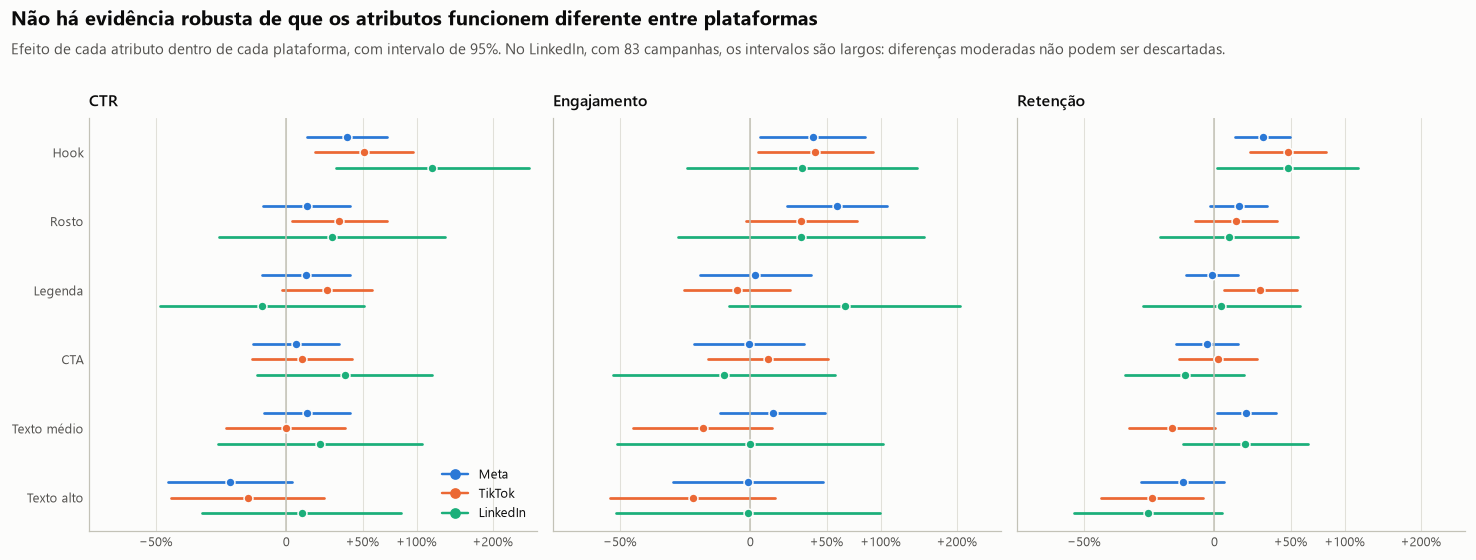

In [17]:
SHORT_TERMS = dict(zip(CREATIVE_TERMS.values(),
                       ["Hook", "Rosto", "Legenda", "CTA", "Texto médio", "Texto alto"],
                       strict=True))
FOREST_METRICS = {"ctr": "CTR", "engagement_rate": "Engajamento", "completion_rate": "Retenção"}
by_platform = {
    platform: {
        metric: estimate_effects(sub, metric, controls=CONTEXT_WITHIN_PLATFORM)
        for metric in [*FOREST_METRICS, "roas_non_branding"]
    }
    for platform, sub in df.groupby("platform", observed=True)
}

ticks = [-0.5, 0, 0.5, 1, 2]
fig, axes = plt.subplots(1, 3, figsize=(13.5, 5.2), sharey=True)
offsets = {"Meta": 0.22, "TikTok": 0.0, "LinkedIn": -0.22}
for ax, (metric, title) in zip(axes, FOREST_METRICS.items(), strict=True):
    for platform in PLATFORMS:
        table = by_platform[platform][metric].set_index("atributo")
        for row, attribute in enumerate(SHORT_TERMS):
            y = len(SHORT_TERMS) - 1 - row + offsets[platform]
            est = table.loc[attribute]
            color = viz.PLATFORM_COLORS[platform]
            ax.plot(np.log1p([est["ic_inferior"], est["ic_superior"]]), [y, y],
                    color=color, linewidth=1.8, solid_capstyle="round")
            ax.scatter(np.log1p(est["efeito"]), y, s=34, color=color,
                       edgecolor=viz.SURFACE, linewidth=1, zorder=3)
    ax.axvline(0, color=viz.BASELINE, linewidth=1)
    ax.set_xticks(np.log1p(ticks), ["−50%", "0", "+50%", "+100%", "+200%"])
    ax.set_xlim(np.log1p(-0.65), np.log1p(2.8))
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(SHORT_TERMS)), list(SHORT_TERMS.values())[::-1])
axes[0].legend(
    handles=[
        Line2D([], [], marker="o", linestyle="-", color=viz.PLATFORM_COLORS[p], label=p)
        for p in PLATFORMS
    ],
    loc="lower right",
)
viz.add_header(
    fig,
    "Não há evidência robusta de que os atributos funcionem diferente entre plataformas",
    "Efeito de cada atributo dentro de cada plataforma, com intervalo de 95%. No LinkedIn, com "
    "83 campanhas, os intervalos são largos: diferenças moderadas não podem ser descartadas.",
)
viz.save(fig, "02_efeito_por_plataforma")
plt.show()

Agora o teste direto: para cada atributo e métrica, o p-valor da hipótese de que o efeito é o mesmo nas três plataformas. Abaixo de 0,05 indicaria diferença.

In [18]:
HETEROGENEITY_ATTRIBUTES = {
    "has_hook": "Hook",
    "has_face": "Rosto",
    "subtitle_status": "Legenda",
    "has_cta": "CTA",
    "text_density": "Densidade de texto",
    "musica_decimos": "Música/voz",
}
HETEROGENEITY_METRICS = {**FOREST_METRICS, "roas_non_branding": "ROAS", TARGET: "Klike Score"}
platform_tests = pd.DataFrame(
    {
        label: {
            attr_label: interaction_pvalue(df, attribute, metric, log=metric != TARGET)
            for attribute, attr_label in HETEROGENEITY_ATTRIBUTES.items()
        }
        for metric, label in HETEROGENEITY_METRICS.items()
    }
)
display(platform_tests.round(3))
q_values = stats.false_discovery_control(platform_tests.to_numpy().ravel(), method="bh")
print(
    f"{platform_tests.size} testes | p < 0,05: {(platform_tests < 0.05).sum().sum()} "
    f"(esperado só por acaso: {fmt_number(platform_tests.size * 0.05, 1)}) | "
    f"significativos depois da correção para múltiplos testes: {(q_values < 0.05).sum()}"
)

,CTR,Engajamento,Retenção,ROAS,Klike Score
Hook,0.211,0.923,0.641,0.802,0.149
Rosto,0.400,0.324,0.894,0.343,0.621
Legenda,0.129,0.084,0.158,0.680,0.066
CTA,0.934,0.609,0.452,0.641,0.530
Densidade de texto,0.491,0.562,0.017,0.685,0.550
Música/voz,0.363,0.076,0.559,0.023,0.030


30 testes | p < 0,05: 3 (esperado só por acaso: 1,5) | significativos depois da correção para múltiplos testes: 0


**Nenhuma diferença entre plataformas é robusta.** Dos 30 testes, 3 ficam abaixo de 0,05, contra 1,5 esperados por acaso, e nenhum resiste à correção para múltiplos testes. Os três ficam como indícios, para acompanhar com mais dados: no TikTok, o texto parece pesar mais contra a retenção e a música, mais contra o score; a música também mostra um indício no ROAS.

A resposta à pergunta do desafio, portanto, é: **não há evidência de que o que funciona no TikTok deixe de funcionar no LinkedIn.** Isso é diferente de provar que os efeitos são iguais. No LinkedIn, com 83 campanhas, os intervalos são largos: na tabela abaixo, o efeito do rosto no engajamento pode ir de −32% a +152%. A base é compatível com efeitos iguais, mas também com diferenças moderadas. O que muda com segurança é o patamar de cada plataforma e o formato, a seguir.

As tabelas abaixo trazem os efeitos de cada plataforma com seus intervalos, para referência:

In [19]:
for platform in PLATFORMS:
    print(f"\n{platform}")
    display(effects_with_ci(by_platform[platform], {**FOREST_METRICS, "roas_non_branding": "ROAS"}))


Meta


,CTR (n=241),Engajamento (n=224),Retenção (n=213),ROAS (n=206)
atributo,,,,
Hook nos 3 primeiros segundos,"+38% [+11%, +71%]","+39% [+5%, +84%]","+29% [+12%, +50%]","−9% [−25%, +11%]"
Rosto humano,"+12% [−11%, +40%]","+58% [+22%, +106%]","+14% [−2%, +32%]","−1% [−20%, +23%]"
Legenda,"+11% [−12%, +41%]","+3% [−24%, +38%]","−1% [−14%, +13%]","0% [−18%, +23%]"
Call-to-action,"+5% [−16%, +33%]","−1% [−26%, +33%]","−4% [−19%, +13%]","+9% [−13%, +36%]"
Texto médio (vs. baixo),"+12% [−11%, +40%]","+13% [−15%, +49%]","+19% [+2%, +38%]","−6% [−23%, +16%]"
Texto alto (vs. baixo),"−26% [−47%, +3%]","−1% [−34%, +47%]","−16% [−32%, +5%]","−32% [−51%, −6%]"



TikTok


,CTR (n=176),Engajamento (n=166),Retenção (n=150),ROAS (n=147)
atributo,,,,
Hook nos 3 primeiros segundos,"+51% [+16%, +97%]","+41% [+4%, +92%]","+48% [+21%, +81%]","0% [−22%, +29%]"
Rosto humano,"+32% [+3%, +70%]","+31% [−2%, +76%]","+12% [−10%, +39%]","−2% [−23%, +27%]"
Legenda,"+24% [−2%, +58%]","−7% [−30%, +24%]","+28% [+5%, +55%]","+10% [−15%, +41%]"
Call-to-action,"+9% [−17%, +42%]","+10% [−20%, +51%]","+2% [−17%, +25%]","+1% [−21%, +30%]"
Texto médio (vs. baixo),"0% [−27%, +36%]","−22% [−46%, +12%]","−20% [−36%, 0%]","−6% [−27%, +22%]"
Texto alto (vs. baixo),"−19% [−46%, +22%]","−26% [−53%, +14%]","−28% [−45%, −6%]","−12% [−38%, +25%]"



LinkedIn


,CTR (n=83),Engajamento (n=78),Retenção (n=74),ROAS (n=71)
atributo,,,,
Hook nos 3 primeiros segundos,"+118% [+30%, +264%]","+32% [−29%, +142%]","+48% [+1%, +115%]","+8% [−40%, +97%]"
Rosto humano,"+27% [−30%, +132%]","+31% [−32%, +152%]","+8% [−25%, +56%]","+34% [−36%, +181%]"
Legenda,"−12% [−49%, +52%]","+65% [−11%, +205%]","+4% [−32%, +58%]","+21% [−36%, +127%]"
Call-to-action,"+36% [−14%, +117%]","−13% [−52%, +57%]","−15% [−38%, +17%]","−20% [−53%, +39%]"
Texto médio (vs. baixo),"+20% [−30%, +106%]","0% [−51%, +102%]","+18% [−15%, +64%]","−28% [−65%, +50%]"
Texto alto (vs. baixo),"+9% [−36%, +84%]","−1% [−51%, +99%]","−30% [−53%, +4%]","−39% [−69%, +20%]"


### 3.3 E por público, categoria e objetivo?

O mesmo teste, agora perguntando se o efeito do hook e do rosto muda com a faixa etária, a categoria do anunciante ou o objetivo da campanha:

In [20]:
MODERATORS = {
    "C(target_audience_age)": "faixa etária",
    "C(category)": "categoria",
    "C(objective)": "objetivo",
}
segment_tests = pd.DataFrame(
    {
        f"{attr_label} × {mod_label}": {
            label: interaction_pvalue(df, attribute, metric, moderator=moderator,
                                      log=metric != TARGET)
            for metric, label in {"ctr": "CTR", "engagement_rate": "Engajamento",
                                  TARGET: "Klike Score"}.items()
        }
        for attribute, attr_label in [("has_hook", "Hook"), ("has_face", "Rosto")]
        for moderator, mod_label in MODERATORS.items()
    }
).T
display(segment_tests.round(3))
segment_q = stats.false_discovery_control(segment_tests.to_numpy().ravel(), method="bh")
print(
    f"{segment_tests.size} testes | p < 0,05: {(segment_tests < 0.05).sum().sum()} "
    f"(esperado só por acaso: {fmt_number(segment_tests.size * 0.05, 1)}) | "
    f"significativos depois da correção para múltiplos testes: {(segment_q < 0.05).sum()}"
)

,CTR,Engajamento,Klike Score
Hook × faixa etária,0.536,0.029,0.247
Hook × categoria,0.695,0.172,0.272
Hook × objetivo,0.943,0.156,0.120
Rosto × faixa etária,0.074,0.368,0.399
Rosto × categoria,0.961,0.548,0.419
Rosto × objetivo,0.176,0.956,0.203


18 testes | p < 0,05: 1 (esperado só por acaso: 0,9) | significativos depois da correção para múltiplos testes: 0


Também não aparece diferença robusta: um único teste em 18 fica abaixo de 0,05, o que o acaso explica, e ele não resiste à correção. Em particular, **o efeito do rosto no engajamento não muda de forma detectável com a faixa etária.** O contexto da campanha muda o patamar das métricas, mas não há evidência de que mude o efeito dos atributos do criativo.

### 3.4 Formato do vídeo

O formato fica fora do teste anterior porque depende da plataforma: o TikTok não tem nenhum vídeo horizontal. Aqui, cada formato é comparado com o formato mais usado em cada plataforma, mantendo o resto igual.

resultado                                               Klike Score  \
plataforma formato    referência campanhas                            
Meta       quadrado   vertical   68         +0,6 pts (inconclusivo)   
           horizontal vertical   67                        −5,1 pts   
TikTok     quadrado   vertical   24         −3,7 pts (inconclusivo)   
LinkedIn   quadrado   horizontal 28         −4,4 pts (inconclusivo)   
           vertical   horizontal 11         −9,3 pts (inconclusivo)   

resultado                                           Engajamento  
plataforma formato    referência campanhas                       
Meta       quadrado   vertical   68         −28% (inconclusivo)  
           horizontal vertical   67                        −39%  
TikTok     quadrado   vertical   24          −9% (inconclusivo)  
LinkedIn   quadrado   horizontal 28         −37% (inconclusivo)  
           vertical   horizontal 11         −26% (inconclusivo)

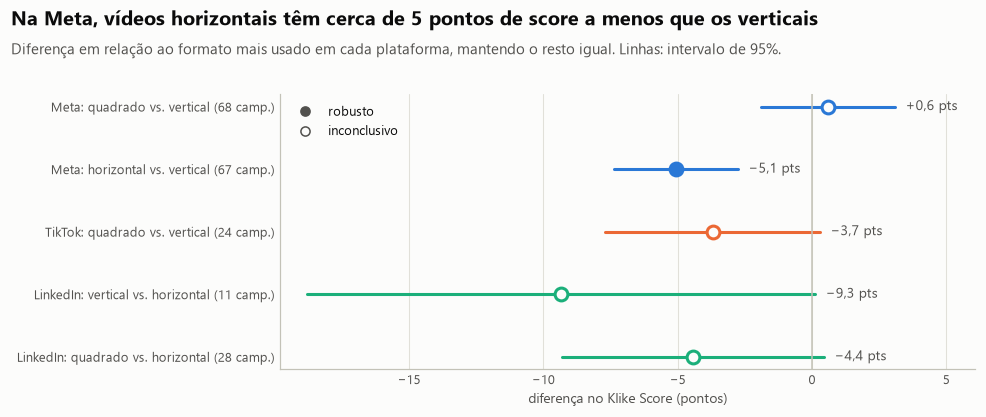

In [21]:
most_used_format = (
    df.groupby("platform", observed=True)["format"]
    .agg(lambda s: s.astype(str).value_counts().idxmax())
    .to_dict()
)
format_rows = []
for platform in PLATFORMS:
    reference = most_used_format[platform]
    sub = df[df["platform"] == platform]
    term = f"C(format, Treatment('{reference}'))"
    for outcome, log in [(TARGET, False), ("engagement_rate", True)]:
        fit = fit_model(sub, outcome, log=log, controls=CONTEXT_WITHIN_PLATFORM, extra=term)
        names = {t: t.split("[T.")[1].rstrip("]") for t in fit.params.index if t.startswith(term)}
        table = tidy_effects(fit, names, log=log)
        table["plataforma"], table["referência"], table["resultado"] = platform, reference, outcome
        table["campanhas"] = table["atributo"].map(sub["format"].astype(str).value_counts())
        format_rows.append(table)
formats = add_evidence(
    pd.concat(format_rows, ignore_index=True).rename(columns={"atributo": "formato"})
)
formats["leitura"] = [
    (fmt_signed(r.efeito, 1, " pts") if r.resultado == TARGET else fmt_signed_pct(r.efeito))
    + LEVEL_SUFFIX[r.evidencia]
    for r in formats.itertuples()
]
display(
    formats.pivot_table(
        index=["plataforma", "formato", "referência", "campanhas"],
        columns="resultado",
        values="leitura",
        aggfunc="first",
        sort=False,
    ).rename(columns={TARGET: "Klike Score", "engagement_rate": "Engajamento"})
)

score_formats = formats[formats["resultado"] == TARGET].reset_index(drop=True)
fill = {"robusto": 1.0, "indício": 0.35, "inconclusivo": 0.0}  # opacidade do marcador


def marker_fill(color, level: str):
    """Marcador cheio para robusto, meio apagado para indício, vazio para inconclusivo."""
    return to_rgba(color, fill[level]) if fill[level] else viz.SURFACE


fig, ax = plt.subplots(figsize=(9, 3.9))
for y, row in score_formats.iloc[::-1].reset_index(drop=True).iterrows():
    color = viz.PLATFORM_COLORS[row["plataforma"]]
    ax.plot([row["ic_inferior"], row["ic_superior"]], [y, y], color=color, linewidth=2)
    ax.scatter(
        row["efeito"], y, s=70, zorder=3, linewidth=2, edgecolor=color,
        color=marker_fill(color, row["evidencia"]),
    )
    ax.text(
        row["ic_superior"] + 0.4, y, fmt_signed(row["efeito"], 1, " pts"),
        va="center", fontsize=9, color=viz.INK_SECONDARY,
    )
labels = [
    f"{r.plataforma}: {r.formato} vs. {r.referência} ({r.campanhas} camp.)"
    for r in score_formats.iloc[::-1].itertuples()
]
ax.set_yticks(range(len(labels)), labels)
ax.axvline(0, color=viz.BASELINE, linewidth=1)
ax.set_xlabel("diferença no Klike Score (pontos)")
ax.grid(axis="y", visible=False)
ax.set_xlim(score_formats["ic_inferior"].min() - 1, score_formats["ic_superior"].max() + 3)
ax.legend(
    handles=[
        Line2D([], [], marker="o", linestyle="", markeredgecolor=viz.INK_SECONDARY,
               markerfacecolor=marker_fill(viz.INK_SECONDARY, level), label=level)
        for level in EVIDENCE_LEVELS
        if level in set(score_formats["evidencia"])
    ],
    loc="upper left",
)
viz.add_header(
    fig,
    "Na Meta, vídeos horizontais têm cerca de 5 pontos de score a menos que os verticais",
    "Diferença em relação ao formato mais usado em cada plataforma, mantendo o resto igual. "
    "Linhas: intervalo de 95%.",
)
viz.save(fig, "02_formato")
plt.show()

- **Meta:** vídeos horizontais têm cerca de 5 pontos de score e quase 40% de engajamento a menos que os verticais, dois resultados robustos. Quadrado e vertical empatam.
- **TikTok e LinkedIn:** a direção é a mesma, a favor do formato mais usado na plataforma, vertical no TikTok e horizontal no LinkedIn. Mas os intervalos cruzam o zero, então isso fica como tendência, não como conclusão.

### 3.5 Duração do vídeo

O senso comum diz que vídeos curtos performam melhor, principalmente no TikTok. Os dados desta base não confirmam isso.

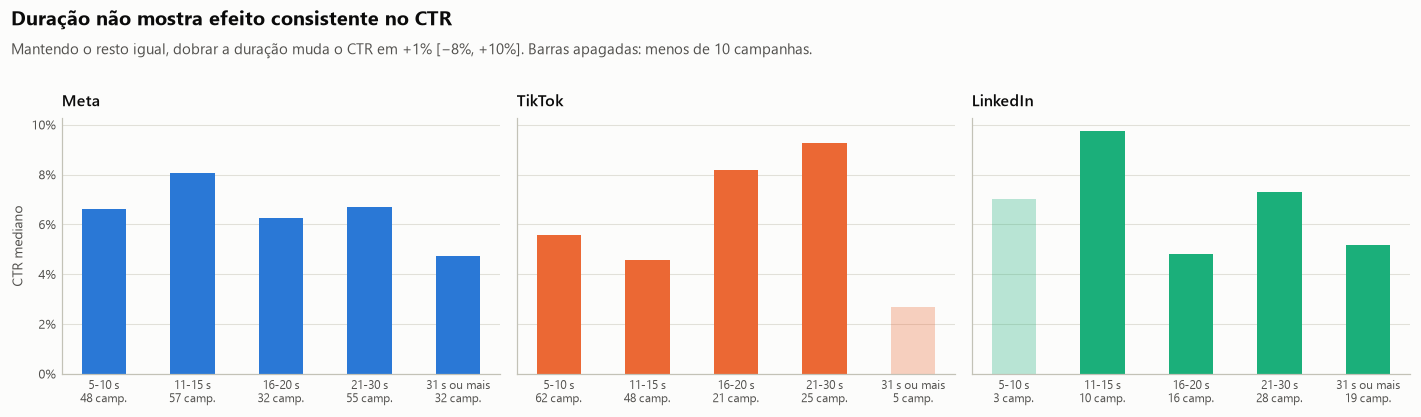

,CTR,Retenção,Klike Score
efeito de dobrar a duração,,,
Todas,"+1% [−8%, +10%]","0% [−6%, +6%]","−0,3 pts [−1,4 pts, +0,8 pts]"
Meta,"−4% [−16%, +9%]","−1% [−9%, +8%]","−0,3 pts [−1,5 pts, +0,9 pts]"
TikTok,"+8% [−11%, +32%]","−1% [−14%, +13%]","−0,7 pts [−3,0 pts, +1,5 pts]"
LinkedIn,"+20% [−16%, +71%]","+12% [−4%, +29%]","+2,9 pts [−1,5 pts, +7,3 pts]"


12 testes | p < 0,05: 0


In [22]:
def doubling_effect(data, outcome, log, controls):
    """Efeito de dobrar a duração, mantendo o resto igual: texto com intervalo e p-valor."""
    term = "np.log(video_duration_s)"
    fit = fit_model(data.dropna(subset=["video_duration_s"]), outcome, log=log,
                    controls=controls, extra=term)
    estimate = np.array([fit.params[term], *fit.conf_int().loc[term]])
    if log:
        low_high = [fmt_signed_pct(v) for v in 2**estimate - 1]
    else:
        low_high = [fmt_signed(v, 1, " pts") for v in estimate * np.log(2)]
    return f"{low_high[0]} [{low_high[1]}, {low_high[2]}]", fit.pvalues[term]


bands = pd.cut(
    df["video_duration_s"], [0, 10, 15, 20, 30, np.inf],
    labels=["5-10 s", "11-15 s", "16-20 s", "21-30 s", "31 s ou mais"],
)
by_band = (
    df.assign(faixa=bands)
    .groupby(["platform", "faixa"], observed=False)["ctr"]
    .agg(["median", "size"])
)
overall_doubling, _ = doubling_effect(df, "ctr", True, CONTEXT_FORMULA)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), sharey=True)
for ax, platform in zip(axes, PLATFORMS, strict=True):
    data = by_band.loc[platform]
    colors = [
        viz.PLATFORM_COLORS[platform] if n >= 10 else to_rgba(viz.PLATFORM_COLORS[platform], 0.3)
        for n in data["size"]
    ]
    x = np.arange(len(data))
    ax.bar(x, data["median"].fillna(0), width=0.5, color=colors)
    ax.set_xticks(x, [f"{band}\n{n} camp." for band, n in data["size"].items()], fontsize=8)
    ax.set_title(platform)
    ax.grid(axis="x", visible=False)
axes[0].yaxis.set_major_formatter(viz.pct_formatter)
axes[0].set_ylabel("CTR mediano")
viz.add_header(
    fig,
    "Duração não mostra efeito consistente no CTR",
    f"Mantendo o resto igual, dobrar a duração muda o CTR em {overall_doubling}. "
    "Barras apagadas: menos de 10 campanhas.",
)
viz.save(fig, "02_duracao")
plt.show()

outcomes = {"ctr": "CTR", "completion_rate": "Retenção", TARGET: "Klike Score"}
duration_tests = {
    "Todas": {label: doubling_effect(df, m, m != TARGET, CONTEXT_FORMULA)
              for m, label in outcomes.items()}
}
for platform in PLATFORMS:
    sub = df[df["platform"] == platform]
    duration_tests[platform] = {
        label: doubling_effect(sub, m, m != TARGET, CONTEXT_WITHIN_PLATFORM)
        for m, label in outcomes.items()
    }
display(
    pd.DataFrame(
        {group: {label: text for label, (text, _) in results.items()}
         for group, results in duration_tests.items()}
    ).T.rename_axis("efeito de dobrar a duração")
)
duration_p = [p for results in duration_tests.values() for _, p in results.values()]
print(f"{len(duration_p)} testes | p < 0,05: {sum(p < 0.05 for p in duration_p)}")

No gráfico, o CTR mediano do TikTok parece subir com a duração. Mas essa leitura é bruta: vídeos de durações diferentes também diferem em hook, rosto e público. Com o resto mantido igual, nenhum dos 12 testes fica abaixo de 0,05: nenhuma plataforma mostra efeito detectável da duração em CTR, retenção ou score. Há também um limite de amostra: só 5 vídeos de TikTok têm mais de 30 segundos.

**Consequência prática:** o recommendations engine não vai sugerir mudar a duração com base nestes dados. Seria uma recomendação sem evidência.

### 3.6 Resumo

**O que não mostrou diferença entre plataformas,** com os efeitos gerais da seção 2:

| Atributo | Associação |
| :-- | :-- |
| Hook | CTR, engajamento e retenção maiores |
| Rosto humano | Engajamento e CTR maiores; indício de retenção maior |
| Densidade de texto alta | Retenção e ROAS menores |
| Legenda, CTA | Sem efeito robusto em performance; mais pontos no score |
| Duração | Sem efeito detectável |

**O que muda de uma plataforma para outra:**

| | Meta | TikTok | LinkedIn |
| :-- | :-- | :-- | :-- |
| **Patamar** | Referência | Engajamento bem maior; CPC mais baixo; maior ROAS | CPC de 4 a 5 vezes o do TikTok; ROAS mediano abaixo de 1 |
| **Formato** | Horizontal com score e engajamento menores | Tendência a favor do vertical | Tendência a favor do horizontal |
| **Indícios** | | Texto pesa mais contra a retenção; música, contra o score | |

## 4. Parte 1.4 · As visualizações para o time de marketing

Cada gráfico responde uma pergunta e tem um título que já diz a resposta. Todos estão em `reports/figures/`.

| Gráfico | Pergunta que responde | Mensagem |
| :-- | :-- | :-- |
| `02_boas_praticas.png` | Vale a pena seguir as boas práticas? | Cada prática a mais vem com cerca de 11 pontos de score |
| `02_efeitos_geral.png` | Onde o criativo faz diferença? | Hook e rosto se associam a mais atenção; conversão e ROAS variam mais com o público |
| `02_patamares_por_plataforma.png` | As plataformas se comportam igual? | Diferem no custo e no engajamento, não no clique |
| `02_efeito_por_plataforma.png` | O que funciona em uma funciona na outra? | Não há evidência robusta de que os atributos funcionem diferente |
| `02_formato.png` | O formato importa? | Na Meta, o horizontal tem score menor |
| `02_duracao.png` | Vídeos mais curtos performam melhor? | Não nesta base |

Escolhas de design: uma cor fixa por plataforma em todos os gráficos; azul para maior e vermelho para menor; cor forte para resultado robusto, hachura para indício e cor apagada para inconclusivo; e números no padrão brasileiro.

## 5. O que levo para as Partes 2 e 3

- **O score responde fortemente aos atributos do criativo e pouco ao público.** O modelo pré-veiculação da Parte 2 tem boas chances de funcionar.
- **O engine deve ser contextual, partindo dos efeitos gerais.** Não encontramos evidência robusta de que os efeitos mudem entre plataformas, públicos ou categorias, então o efeito geral, o mais preciso, é a referência. O contexto entra no patamar da plataforma e na checagem de formato. A ideia de também usar a evidência de cada segmento, encolhida em direção ao efeito geral na proporção da sua incerteza, foi testada na Parte 3 e descartada por não trazer benefício nesta base (notebook 04, seção 6). Com os efeitos gerais e o suporte histórico, um grupo pequeno não gera recomendação baseada em ruído, e os indícios aparecem sinalizados como tal.
- **Hook e rosto vêm primeiro**, por terem os maiores efeitos em performance.
- **Toda recomendação deve trazer seu nível de evidência e separar score de performance.** Recomendar um CTA tende a subir o score, mas não há evidência de que melhore a performance, e o engine precisa dizer isso.
- **Nada de recomendação sem evidência.** Duração fica de fora pelo que a seção 3.5 mostrou.